In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%%writefile -a /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


# ================= Phase 3: Tiny CNN (final training recipe) =================
import time as _time
import torch
import torch.nn as nn
import torch.nn.functional as _F

COMPACT_FILES = ['X_compact.npy', 'y_labels.npy', 'recording_metadata.csv']


def load_compact():
    """Load compact dataset (90 x 32 x 3) into RAM. Copies from Drive once per session."""
    LOCAL.mkdir(exist_ok=True)
    for f in COMPACT_FILES:
        if not (LOCAL / f).exists():
            shutil.copy2(PROJECT / 'processed' / f, LOCAL / f)
    Xc = np.load(LOCAL / 'X_compact.npy')
    y = np.load(LOCAL / 'y_labels.npy')
    meta = pd.read_csv(LOCAL / 'recording_metadata.csv')
    return Xc, y, meta


class TinyRadarCNN(nn.Module):
    """Edge-sized CNN for compact radar input (in_ch x 90 x 32)."""
    def __init__(self, in_ch=3, num_classes=NUM_CLASSES, widths=(16, 32, 64)):
        super().__init__()
        w1, w2, w3 = widths

        def block(cin, cout, pool):
            layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                      nn.BatchNorm2d(cout), nn.ReLU()]
            if pool:
                layers.append(nn.MaxPool2d(2))
            return layers

        self.features = nn.Sequential(
            *block(in_ch, w1, True), *block(w1, w2, True), *block(w2, w3, False),
            nn.AdaptiveAvgPool2d(1))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(w3, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def prepare_input(Xc, idx, mode='persample', channels=(0, 1, 2)):
    """Per-recording input transform (no cross-subject statistics)."""
    x = Xc[idx][..., list(channels)].astype(np.float32)
    if mode == 'log':
        x = np.log(x + 1e-4)
    elif mode == 'persample':
        x = x / (x.std(axis=(1, 2, 3), keepdims=True) + 1e-8)
    return x


def augment(x, max_t=0, max_r=0, noise=0.0):
    """Random time/range shift (edge-replicate padding) + Gaussian noise."""
    B, C, T, R = x.shape
    if max_t or max_r:
        xp = _F.pad(x, (max_r, max_r, max_t, max_t), mode='replicate')
        ts = torch.randint(0, 2 * max_t + 1, (B,)).tolist()
        rs = torch.randint(0, 2 * max_r + 1, (B,)).tolist()
        x = torch.stack([xp[i, :, ts[i]:ts[i] + T, rs[i]:rs[i] + R] for i in range(B)])
    if noise > 0:
        x = x + noise * torch.randn_like(x)
    return x


@torch.no_grad()
def predict(model, X, bs=512):
    model.eval()
    return torch.cat([model(X[s:s + bs]).argmax(1)
                      for s in range(0, len(X), bs)]).cpu().numpy()


def train_cnn_fold(Xc, y, fold, device, mode='persample', channels=(0, 1, 2),
                   aug=None, widths=(16, 32, 64), epochs=60, patience=15,
                   min_epochs=20, batch_size=64, lr=1e-3, seed=None):
    """Final training recipe from Phase 3."""
    aug = aug or {}
    seed = SEED if seed is None else seed
    set_seed(seed + fold['fold'])
    tr, va, te = fold['train_idx'], fold['val_idx'], fold['test_idx']

    xtr = prepare_input(Xc, tr, mode, channels)
    mean = xtr.mean(axis=(0, 1, 2))
    std = xtr.std(axis=(0, 1, 2))

    def to_t(x, idx):
        x = np.transpose((x - mean) / std, (0, 3, 1, 2))
        return (torch.tensor(x, dtype=torch.float32, device=device),
                torch.tensor(y[idx], device=device))

    Xtr, ytr = to_t(xtr, tr)
    Xva, yva = to_t(prepare_input(Xc, va, mode, channels), va)
    Xte, _ = to_t(prepare_input(Xc, te, mode, channels), te)
    del xtr

    model = TinyRadarCNN(in_ch=len(channels), widths=widths).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()

    best_f1, best_ep, best_state, bad = -1.0, 0, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), device=device)
        for s in range(0, len(perm), batch_size):
            b = perm[s:s + batch_size]
            if len(b) < 2:
                continue
            opt.zero_grad()
            loss_fn(model(augment(Xtr[b], **aug)), ytr[b]).backward()
            opt.step()
        sched.step()

        val_f1 = evaluate(yva.cpu().numpy(), predict(model, Xva))['macro_f1']
        if val_f1 > best_f1:
            best_f1, best_ep, bad = val_f1, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience and ep >= min_epochs:
                break

    model.load_state_dict(best_state)
    return {'model': model, 'y_pred': predict(model, Xte), 'val_f1': best_f1,
            'best_epoch': best_ep, 'last_epoch': ep, 'mean': mean, 'std': std}


def run_cnn_loso(Xc, y, meta, device, tag, save_models=False, verbose=True, **kwargs):
    """Train/evaluate the CNN on all 8 LOSO folds. Saves results (and optionally models)."""
    rows, preds = [], []
    t0 = _time.time()
    for fold in loso_folds(meta):
        r = train_cnn_fold(Xc, y, fold, device, **kwargs)
        te = fold['test_idx']
        m = evaluate(y[te], r['y_pred'])
        rows.append({'model': tag, 'fold': fold['fold'],
                     'test_subject': fold['test_subject'], **m,
                     'best_epoch': r['best_epoch']})
        preds.append(pd.DataFrame({'model': tag, 'fold': fold['fold'], 'idx': te,
                                   'y_true': y[te], 'y_pred': r['y_pred']}))
        if save_models:
            torch.save({'state_dict': r['model'].state_dict(), 'mean': r['mean'],
                        'std': r['std'], 'config': kwargs},
                       PROJECT / 'models' / f"{tag}_fold{fold['fold']}.pt")
        if verbose:
            print(f"[{tag}] Fold {fold['fold']} (S{fold['test_subject']}) | "
                  f"best ep={r['best_epoch']:2d}/{r['last_epoch']:2d} | "
                  f"TEST F1={m['macro_f1']:.3f}")
    df = pd.DataFrame(rows)
    save_results(df, f'loso_{tag}')
    save_results(pd.concat(preds), f'loso_{tag}_predictions')
    print(f"[{tag}] mean F1 = {df.macro_f1.mean() * 100:.1f} | "
          f"worst = {df.macro_f1.min() * 100:.1f} | {(_time.time() - t0) / 60:.1f} min")
    return df

Appending to /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


In [3]:
import sys, importlib
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, '/content/drive/MyDrive/RadarGestureEdgeAI')
import radar_utils as ru
importlib.reload(ru)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

Xc, y, meta = ru.load_compact()
print("Xc:", Xc.shape)

Device: cuda
Xc: (9593, 90, 32, 3)


In [5]:
combos = {
    'L': (0,), 'T': (1,), 'R': (2,),
    'L+T': (0, 1), 'L+R': (0, 2), 'T+R': (1, 2),
    'L+T+R': (0, 1, 2),
}

# Load finished combos from Drive; train only the missing ones
sens = {}
for name, ch in combos.items():
    tag = f"sensor_{name.replace('+', '')}"
    path = ru.PROJECT / 'results' / f'loso_{tag}.csv'
    if path.exists():
        sens[name] = pd.read_csv(path)
        print(f"{name:6s}: loaded from Drive")
    else:
        print(f"{name:6s}: training...")
        sens[name] = ru.run_cnn_loso(Xc, y, meta, DEVICE, tag=tag,
                                     channels=ch, verbose=False)

rows = []
for name, d in sens.items():
    n = len(combos[name])
    rows.append({'radars': name, 'n_radars': n,
                 'input_values': 90 * 32 * n,
                 'params': ru.count_params(ru.TinyRadarCNN(in_ch=n)),
                 'mean_F1': d.macro_f1.mean() * 100,
                 'std_F1': d.macro_f1.std() * 100,
                 'worst_F1': d.macro_f1.min() * 100})

tab = (pd.DataFrame(rows).round(1)
         .sort_values(['n_radars', 'mean_F1'], ascending=[True, False]))
print("\n===== SENSOR ABLATION (TinyCNN, LOSO, %) =====")
print(tab.to_string(index=False))
ru.save_results(tab, 'table_sensor_ablation')

print("\n===== Macro-F1 per test subject (%) =====")
per = pd.concat({k: v.set_index('test_subject').macro_f1 * 100
                 for k, v in sens.items()}, axis=1).round(1)
print(per.to_string())

L     : loaded from Drive
T     : loaded from Drive
R     : loaded from Drive
L+T   : loaded from Drive
L+R   : loaded from Drive
T+R   : loaded from Drive
L+T+R : training...
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_sensor_LTR.csv
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_sensor_LTR_predictions.csv
[sensor_LTR] mean F1 = 89.5 | worst = 83.7 | 2.9 min

===== SENSOR ABLATION (TinyCNN, LOSO, %) =====
radars  n_radars  input_values  params  mean_F1  std_F1  worst_F1
     L         1          2880   24188     62.7     9.9      48.5
     R         1          2880   24188     60.0     5.3      52.2
     T         1          2880   24188     57.5     4.0      52.4
   T+R         2          5760   24332     87.8     8.2      76.0
   L+T         2          5760   24332     87.6     6.7      73.8
   L+R         2          5760   24332     74.7     6.1      65.1
 L+T+R         3          8640   24476     89.5     4.3      83.7
Saved: /content/drive/MyDrive

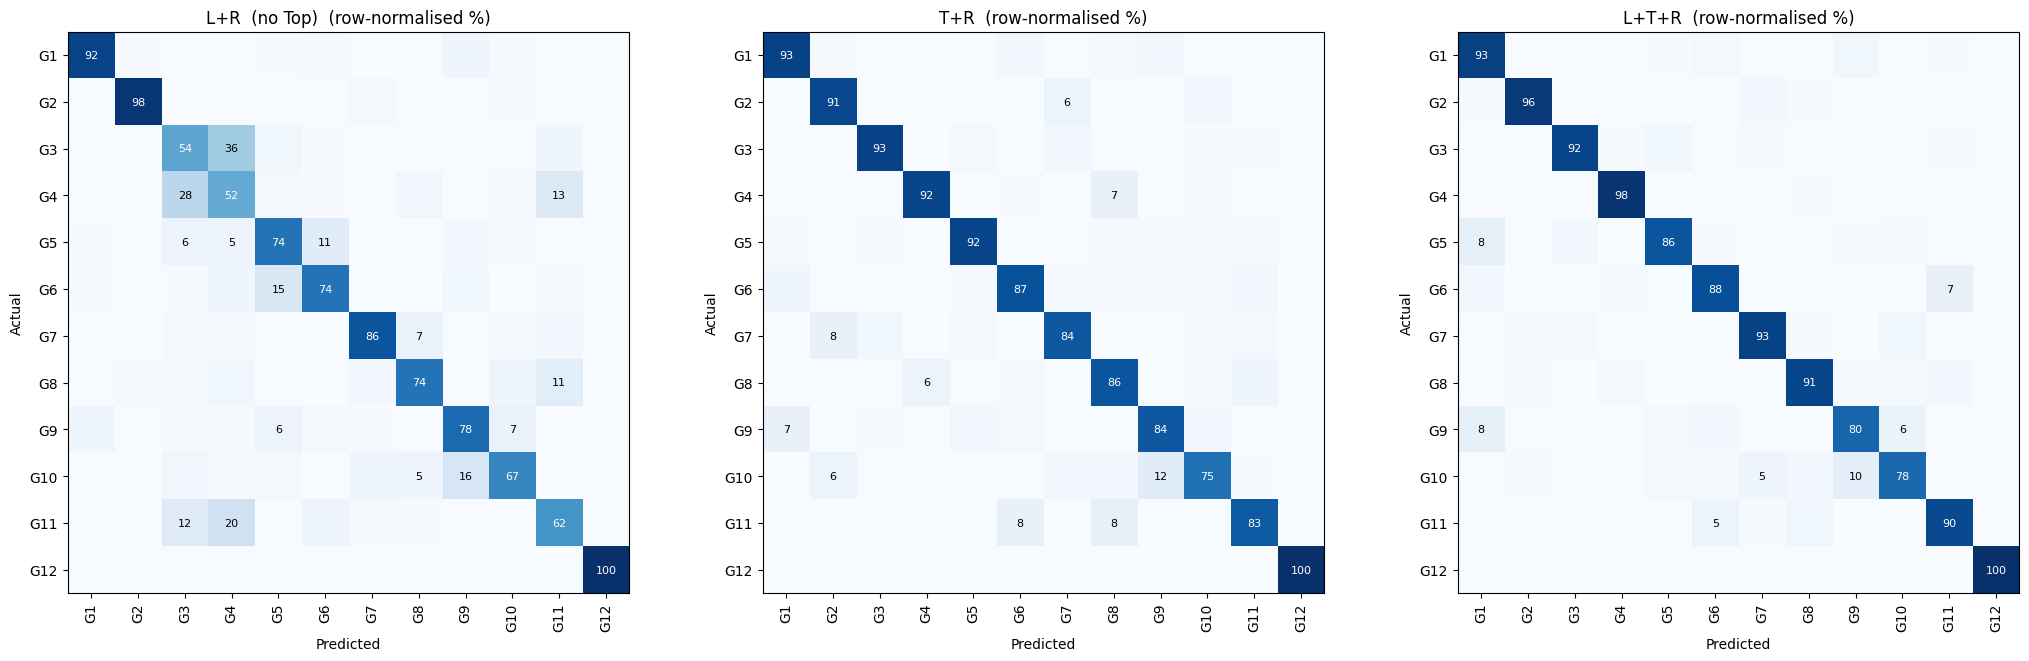

===== TOP 8 CONFUSIONS WITHOUT TOP RADAR (L+R) =====
  Actual G3  -> predicted G4 :  36.4%
  Actual G4  -> predicted G3 :  27.7%
  Actual G11 -> predicted G4 :  19.7%
  Actual G10 -> predicted G9 :  16.1%
  Actual G6  -> predicted G5 :  15.0%
  Actual G4  -> predicted G11:  13.2%
  Actual G11 -> predicted G3 :  12.1%
  Actual G5  -> predicted G6 :  11.4%

===== PER-GESTURE RECALL: effect of adding the Top radar (%) =====
gesture  recall L+R  recall L+T+R  gain from Top
     G4        51.8          98.0           46.2
     G3        54.1          92.0           37.9
    G11        61.6          90.4           28.9
     G8        73.9          91.1           17.2
     G6        74.1          88.1           14.0
     G5        74.4          85.9           11.5
    G10        67.0          78.1           11.1
     G7        85.9          92.6            6.8
     G9        77.6          79.6            2.0
     G1        92.2          93.4            1.1
    G12        99.6          99.6   

In [6]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

def load_preds(tag):
    return pd.read_csv(ru.PROJECT / 'results' / f'loso_{tag}_predictions.csv')

def norm_cm(tag):
    p = load_preds(tag)
    return confusion_matrix(p.y_true, p.y_pred, labels=range(12), normalize='true') * 100

labels = [f'G{k}' for k in range(1, 13)]
configs = [('L+R  (no Top)', 'sensor_LR'), ('T+R', 'sensor_TR'), ('L+T+R', 'sensor_LTR')]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (title, tag) in zip(axes, configs):
    cm = norm_cm(tag)
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=100)
    for i in range(12):
        for j in range(12):
            if cm[i, j] >= 5:
                ax.text(j, i, f'{cm[i, j]:.0f}', ha='center', va='center', fontsize=8,
                        color='white' if cm[i, j] > 50 else 'black')
    ax.set_xticks(range(12)); ax.set_xticklabels(labels, rotation=90)
    ax.set_yticks(range(12)); ax.set_yticklabels(labels)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'{title}  (row-normalised %)')
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_sensor_confusion.png', dpi=200)
plt.show()

# Biggest confusions without the Top radar
cm_lr = norm_cm('sensor_LR')
np.fill_diagonal(cm_lr, 0)
pairs = sorted(((cm_lr[i, j], i, j) for i in range(12) for j in range(12)), reverse=True)[:8]
print("===== TOP 8 CONFUSIONS WITHOUT TOP RADAR (L+R) =====")
for v, i, j in pairs:
    print(f"  Actual G{i+1:<2d} -> predicted G{j+1:<2d}: {v:5.1f}%")

# Per-gesture recall: how much does adding Top help?
rec_lr = np.diag(norm_cm('sensor_LR'))
rec_ltr = np.diag(norm_cm('sensor_LTR'))
gain = pd.DataFrame({'gesture': labels, 'recall L+R': rec_lr.round(1),
                     'recall L+T+R': rec_ltr.round(1),
                     'gain from Top': (rec_ltr - rec_lr).round(1)})
print("\n===== PER-GESTURE RECALL: effect of adding the Top radar (%) =====")
print(gain.sort_values('gain from Top', ascending=False).to_string(index=False))
ru.save_results(gain, 'table_top_radar_gain')